<!-- This is a template that you should use to generate your lab reports for AE801 course work-->
# **Lab Report: Title of the topic**

# Required packages

In [1]:
# import required packages here
import numpy as np
import matplotlib.pyplot as plt
# do not change line below
#from google.colab import files


# Problem statement

1. To write two algorithms: one for **constant panel strength** and other for **linear panel strength**.
2. These should be 2 different functions: **vortex_panel_method_0()** and **vortex_panel_method_1()** and they should have proper input arguments.
3. For verification of all the results: discuss the convergence, effect of panels and deviation from exact results.
4. Use the algorithm to predict the characteristics of one **symmetrical** and one **non-symmetrical** airfoil. Also plot the $C_p$ plots.
5. Limitations of the algorithms using thickness.

# Approach and numerical method

# Numerical algorithm

To solve for the flow around arbitrary 2D shapes, we discretize the surface of the body into $N$ flat segments called **panels**. This study implements and compares two primary panel formulations:
*   **Constant-Strength Vortex Panel Method ():** Assumes a uniform, constant vortex strength (circulation density $\gamma_j$) along each individual panel.
*   **Linear-Strength Vortex Panel Method ():** Assumes that the vortex strength varies linearly across each panel, sharing nodal values at panel boundaries to ensure continuity.

#### Boundary Conditions & The Kutta Condition
To determine the unknown vortex strengths:
1.  **Zero Normal Velocity (No-Penetration):** At the control point (collocation point) of each panel, the net velocity normal to the panel must be zero.
2.  **Kutta Condition:** To model physical lift on an airfoil, the flow must leave the trailing edge smoothly. This is enforced mathematically by ensuring the vortex strength vanishes or cancels out at the trailing edge ($ \gamma_1 + \gamma_N = 0 $).

---

*  **circle:** Generates the boundary coordinates $(x, y)$ of a unit circular cylinder discretized into $n$ panels.
*   **Air_foil** The final robust generator for NACA 4-digit airfoils. It supports both symmetric (e.g., NACA 0012) and asymmetric (e.g., NACA 2412) cambers, safely handling division-by-zero edge cases at the boundaries.
*   **panel_geometry** Calculates key geometric parameters for each panel from the boundary coordinates, including the control point coordinates $(x_c, y_c)$, panel length $S$, and orientation angle $\theta$.

*   **K_L_Matrix** Computes the geometric influence coefficients $K_{i,j}$ and $L_{i,j}$, which represent the normal and tangential velocity induced at control point $i$ by a unit-strength vortex panel $j$.

In [4]:
'Circular Cylinder'
def circle(n):

  theta =np.linspace(2*np.pi,0,n+1)
  r = 1
  a = r*np.cos(theta)
  b = r*np.sin(theta)
  #a**2 +b**2 == 1
  return (a,b)





In [5]:
#generating 3 random numbers for the NACA airfoil

Max_camber = np.random.randint(1,6)
Max_c_location = np.random.randint(1.5,6)
Thickness = np.random.randint(6,15)

#print(Max_camber,Max_c_location,Thickness)

m = Max_camber/100
p = Max_c_location/10
t = Thickness/100

#print(m,p,t)

In [6]:
def Air_foil0(n,str):
  if str == 'symmetric':
    m = 0
    p = 0
    t = 0.12
  elif str == 'asymmetric':
    m = 2/100
    p = 4/10
    t = 0.12


  i = int(n/2)
  a = np.linspace(0, np.pi, i+1)
  x = 0.5*(1 - np.cos(a))
  #print(x)

  # Corresponding y values
  y_t = 5*t*(0.2969*(x**0.5) - 0.1260*(x) - 0.3516*(x**2) + 0.2843*(x**3) - 0.1036*(x**4)) # y_t is thickness value

  y_c = np.where(x <= p, (m/p**2) * (2*p*x - x**2), (m/(1-p)**2) * ((1 - 2*p) + 2*p*x - x**2))
  #print(y_c)

  # Evaluating x,y values for the upper and lower surfaces.
  # So that the increment in y value due to the camber is perpendicular to the surface and not just along the y-axis
  d_yc = np.where(x <= p, (2*m/p**2) * (p - x),(2*m/(1-p)**2) * (p - x) )

  Theta = np.arctan(d_yc)

  x_u = x - y_t*np.sin(Theta)
  y_u = y_c + y_t*np.cos(Theta)
  x_l = x + y_t*np.sin(Theta)
  y_l = y_c - y_t*np.cos(Theta)
  #print(x_u,x_l)

  x_low = np.flip(x_l)
  y_low = np.flip(y_l)
  #print(x_l)
  X = np.concatenate([x_low,x_u[1:]])
  Y = np.concatenate([y_low,y_u[1:]])
  #print(X[200],X[401])
  #print(X,Y)
  return X,Y

In [7]:
def Air_foil(n,str):
  if str == 'symmetric':
    m = 0
    p = 0
    t = 0.12
  elif str == 'asymmetric':
    m = 2/100
    p = 4/10
    t = 0.12

  i = int(n/2)
  a = np.linspace(0, np.pi, i+1)
  x = 0.5*(1 - np.cos(a))

  # Corresponding y values for the generated x values.
  y_t = 5*t*(0.2969*(x**0.5) - 0.1260*(x) - 0.3516*(x**2) + 0.2843*(x**3) - 0.1036*(x**4))

  # Handle symmetric and asymmetric cases for camber line and its derivative
  if m == 0 or p == 0:
    y_c = np.zeros_like(x)
    d_yc = np.zeros_like(x)
  else:
    # evaluating y values for the x to plot the camber line
    y_c = np.where(x <= p, (m/p**2) * (2*p*x - x**2), (m/(1-p)**2) * ((1 - 2*p) + 2*p*x - x**2))
    # Evaluating derivatives
    d_yc = np.where(x <= p, (2*m/p**2) * (p - x), (2*m/(1-p)**2) * (p - x))

  Theta = np.arctan(d_yc)

  x_u = x - y_t*np.sin(Theta)
  y_u = y_c + y_t*np.cos(Theta)
  x_l = x + y_t*np.sin(Theta)
  y_l = y_c - y_t*np.cos(Theta)

  x_low = np.flip(x_l)
  y_low = np.flip(y_l)

  X = np.concatenate([x_low, x_u[1:]])
  Y = np.concatenate([y_low, y_u[1:]])

  return X, Y

In [8]:
X_airfoil,Y_airfoil = Air_foil(20,'symmetric')
X_circle,Y_circle = circle(10)
print(X_airfoil,Y_airfoil)

[1.         0.97552826 0.9045085  0.79389263 0.6545085  0.5
 0.3454915  0.20610737 0.0954915  0.02447174 0.         0.02447174
 0.0954915  0.20610737 0.3454915  0.5        0.6545085  0.79389263
 0.9045085  0.97552826 1.        ] [ 1.66533454e-17 -3.50136226e-03 -1.30709457e-02 -2.64046500e-02
 -4.06861839e-02 -5.28615020e-02 -5.95567645e-02 -5.77118565e-02
 -4.60488284e-02 -2.58933127e-02  0.00000000e+00  2.58933127e-02
  4.60488284e-02  5.77118565e-02  5.95567645e-02  5.28615020e-02
  4.06861839e-02  2.64046500e-02  1.30709457e-02  3.50136226e-03
 -1.66533454e-17]


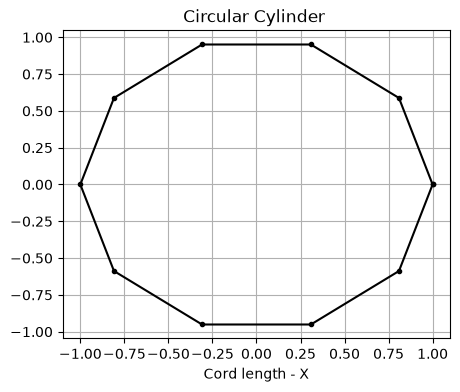

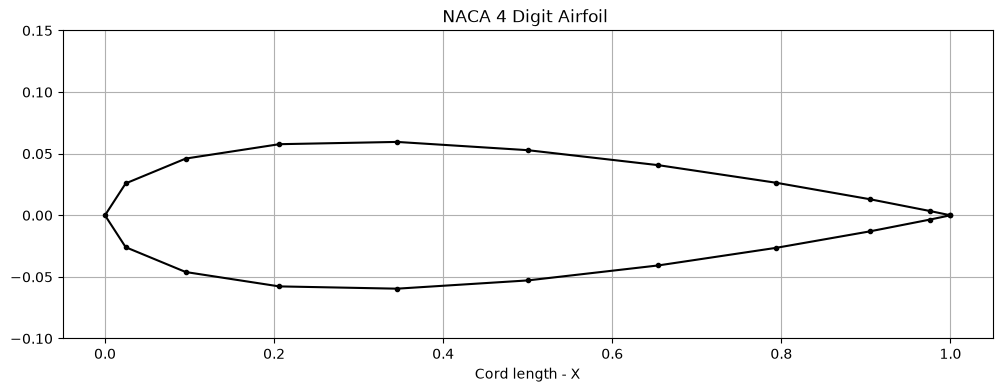

In [9]:
plt.figure(figsize=(5, 4))
plt.plot(X_circle,Y_circle,'o-',color='k',markersize = 3)
plt.title('Circular Cylinder ')
plt.xlabel('Cord length - X')
plt.grid()
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(X_airfoil,Y_airfoil,'o-',color='k',markersize = 3)
#mp.plot(x,y_c,'o-',markersize = 2)
plt.title('NACA 4 Digit Airfoil ')
plt.xlabel('Cord length - X')
plt.ylim(-0.1, 0.15)
plt.grid()
plt.show()



In [10]:
def panel_geometry(x_p,y_p):
  #x_p = np.array(x_p)
  #y_p = np.array(y_p)

  #x and y differeence
  dx = np.diff(x_p)
  dy = np.diff(y_p)
  #print(dx,dy)

  #center point
  x_c = (x_p[:-1] + x_p[1:])/2
  y_c = (y_p[:-1] + y_p[1:])/2
  #print(x_c,y_c)

  length = np.sqrt(dx**2 + dy**2)
  #print(length)

  theta = np.arctan(dy/dx)
  #print(theta)

  return x_c,y_c,length,theta


[0.98776413 0.94001838 0.84920056 0.72420056 0.57725425 0.42274575
 0.27579944 0.15079944 0.05998162 0.01223587 0.01223587 0.05998162
 0.15079944 0.27579944 0.42274575 0.57725425 0.72420056 0.84920056
 0.94001838 0.98776413] [-0.00175068 -0.00828615 -0.0197378  -0.03354542 -0.04677384 -0.05620913
 -0.05863431 -0.05188034 -0.03597107 -0.01294666  0.01294666  0.03597107
  0.05188034  0.05863431  0.05620913  0.04677384  0.03354542  0.0197378
  0.00828615  0.00175068]


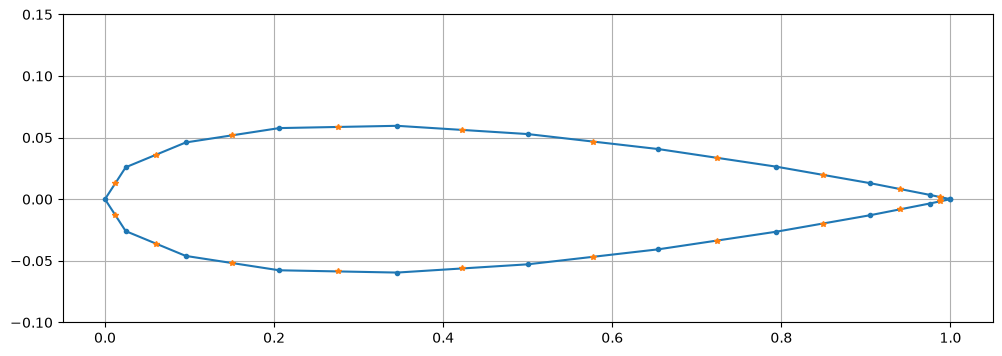

In [11]:
X,Y,S,theta = panel_geometry(X_airfoil,Y_airfoil)
print(X,Y)
plt.figure(figsize=(12, 4))
plt.plot(X_airfoil,Y_airfoil,'o-',markersize = 3)
plt.plot(X,Y,'*',markersize = 4)
plt.ylim(-0.1, 0.15)
plt.grid()
plt.show()

In [12]:
import math as math

def K_L_Matrix(XC,YC,XB,YB,phi,S):
    N_p = len(S)

    K = np.zeros([N_p,N_p])
    L = np.zeros([N_p,N_p])

    for i in range(N_p):
        for j in range(N_p):
            if (j != i):
                A  = -(XC[i]-XB[j])*np.cos(phi[j])-(YC[i]-YB[j])*np.sin(phi[j])
                B  = (XC[i]-XB[j])**2 + (YC[i]-YB[j])**2
                Cn = -np.cos(phi[i]-phi[j])
                Dn = (XC[i]-XB[j])*np.cos(phi[i])+(YC[i]-YB[j])*np.sin(phi[i])
                Ct = np.sin(phi[j]-phi[i])
                Dt = (XC[i]-XB[j])*np.sin(phi[i])-(YC[i]-YB[j])*np.cos(phi[i])
                E  = np.sqrt(B-A**2)
                if (E == 0 or np.iscomplex(E) or np.isnan(E) or np.isinf(E)):
                    K[i,j] = 0
                    L[i,j] = 0
                else:
                    term1  = 0.5*Cn*np.log((S[j]**2 + 2*A*S[j] + B)/B)
                    term2  = ((Dn-A*Cn)/E)*(math.atan2((S[j]+A),E)-math.atan2(A,E))
                    K[i,j] = term1 + term2

                    term1  = 0.5*Ct*np.log((S[j]**2 + 2*A*S[j] + B)/B)
                    term2  = ((Dt-A*Ct)/E)*(math.atan2((S[j]+A),E)-math.atan2(A,E))
                    L[i,j] = term1 + term2

            if (np.iscomplex(K[i,j]) or np.isnan(K[i,j]) or np.isinf(K[i,j])):
                K[i,j] = 0
            if (np.iscomplex(L[i,j]) or np.isnan(L[i,j]) or np.isinf(L[i,j])):
                L[i,j] = 0

    return K, L

In [13]:
def vortex_panel_method_0(xb, yb, alpha_deg, V_inf=1.0):
    alpha = np.deg2rad(alpha_deg)
    xc, yc, S, theta = panel_geometry(xb, yb)
    N = len(S)

    K, L = K_L_Matrix(xc, yc, xb, yb, theta, S)

    A = np.zeros([N, N])
    b = np.zeros(N)

    for i in range(N):
        for j in range(N):
            if i == j:
                A[i, j] = 0.0
            else:
                A[i, j] = -K[i, j]
        b[i] = -V_inf * 2 * np.pi * np.sin(alpha - theta[i])

    'Kutta condition'
    A[N-1, :] = 0.0
    A[N-1, 0] = 1.0
    A[N-1, N-1] = 1.0
    b[N-1] = 0.0

    gamma = np.linalg.solve(A, b)

    V_t = np.zeros(N)
    for i in range(N):
        sum_tangential = 0.0
        for j in range(N):
            sum_tangential += L[i, j] * gamma[j]
        V_t[i] = V_inf * np.cos(alpha - theta[i]) + sum_tangential / (2 * np.pi)

    
    cp = 1.0 - (V_t / V_inf)**2
    Gamma = np.sum(gamma * S)
    chord = np.max(xb) - np.min(xb)
    cl = 2.0 * Gamma / (V_inf * chord)

    return gamma, Gamma, cp, cl, chord, xc, yc

In [14]:
X_airfoil,Y_airfoil = Air_foil(100,'asymmetric')
gamma, Gamma, cp, cl, chord, xc, yc = vortex_panel_method_0(X_airfoil,Y_airfoil,0)
N = len(cp)
#print(gamma, Gamma, cp, cl, chord)


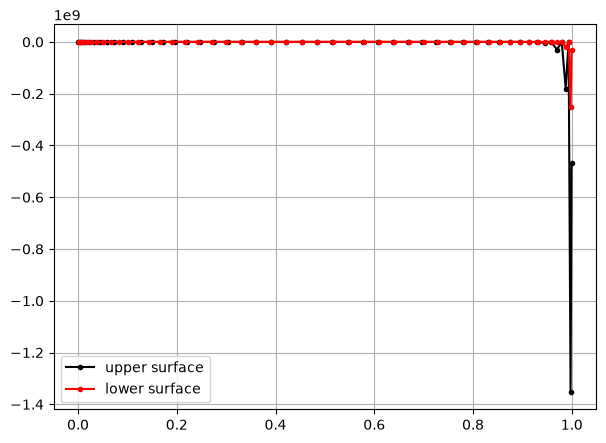

In [15]:
plt.figure(figsize=(7,5))
plt.plot(xc[:int(N*0.5)],cp[:int(N*0.5)],'o-',color = 'k',markersize = 3,label = 'upper surface')
plt.plot(xc[int(N*0.5+1):],cp[int(N*0.5+1):],'o-',color = 'r',markersize = 3,label = 'lower surface')
plt.legend()
plt.grid()
plt.show()

In [40]:

def vortex_panel_method_1(xb, yb, alpha_deg, V_inf=1.0):
    
    alpha = np.deg2rad(alpha_deg)
    xc, yc, S, theta = panel_geometry(xb, yb)
    N = len(S)

    
    K, L = K_L_Matrix(xc, yc, xb, yb, theta, S)

    # Setup system of equations (N+1 equations for N+1 node values)
    A = np.zeros([N + 1, N + 1])
    b = np.zeros(N + 1)

    # Normal velocity boundary conditions at the control points
    for i in range(N):
        for j in range(N):
            A[i, j] += -0.5 * K[i, j]
            A[i, j+1] += -0.5 * K[i, j]
        b[i] = -V_inf * 2 * np.pi * np.sin(alpha - theta[i])

    # Kutta condition: zero vorticity at the trailing edge nodes
    A[N, 0] = 1.0
    A[N, N] = 1.0
    b[N] = 0.0

    # Solve for nodal vortex strengths
    gamma_nodes = np.linalg.solve(A, b)
    gamma_panels = 0.5 * (gamma_nodes[:-1] + gamma_nodes[1:])

    # Compute tangential velocities and Cp at control points
    V_t = np.zeros(N)
    for i in range(N):
        sum_tangential = 0.0
        for j in range(N):
            sum_tangential += L[i, j] * gamma_panels[j]
        V_t[i] = V_inf * np.cos(alpha - theta[i]) + sum_tangential / (2 * np.pi)

    cp = 1.0 - (V_t / V_inf)**2
    Gamma = np.sum(gamma_panels * S)
    chord = np.max(xb) - np.min(xb)
    cl = 2.0 * Gamma / (V_inf * chord)

    return gamma_panels, Gamma, cp, cl, chord, xc, yc




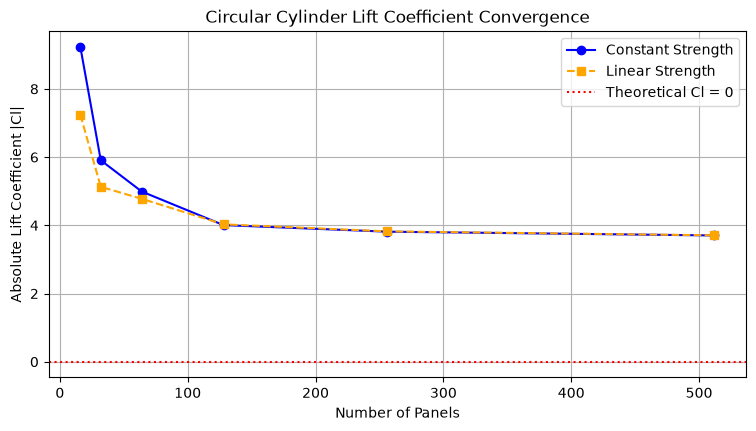

In [41]:
panels_list = [16, 32, 64, 128, 256, 512]
cl_cylinder_0 = []
cl_cylinder_1 = []

for n in panels_list:
    X_c, Y_c = circle(n)
    _, _, _, cl0, _, _, _ = vortex_panel_method_0(X_c, Y_c, 5.0)  
    _, _, _, cl1, _, _, _ = vortex_panel_method_1(X_c, Y_c, 5.0)  
    cl_cylinder_0.append(abs(cl0))
    cl_cylinder_1.append(abs(cl1))


plt.figure(figsize=(9, 4.5))
plt.plot(panels_list, cl_cylinder_0, 'o-', color='blue', label='Constant Strength')
plt.plot(panels_list, cl_cylinder_1, 's--', color='orange', label='Linear Strength')
plt.axhline(y=0.0, color='red', linestyle=':', label='Theoretical Cl = 0')
plt.title('Circular Cylinder Lift Coefficient Convergence')
plt.xlabel('Number of Panels')
plt.ylabel('Absolute Lift Coefficient |Cl|')
plt.legend()
plt.grid()

plt.show()

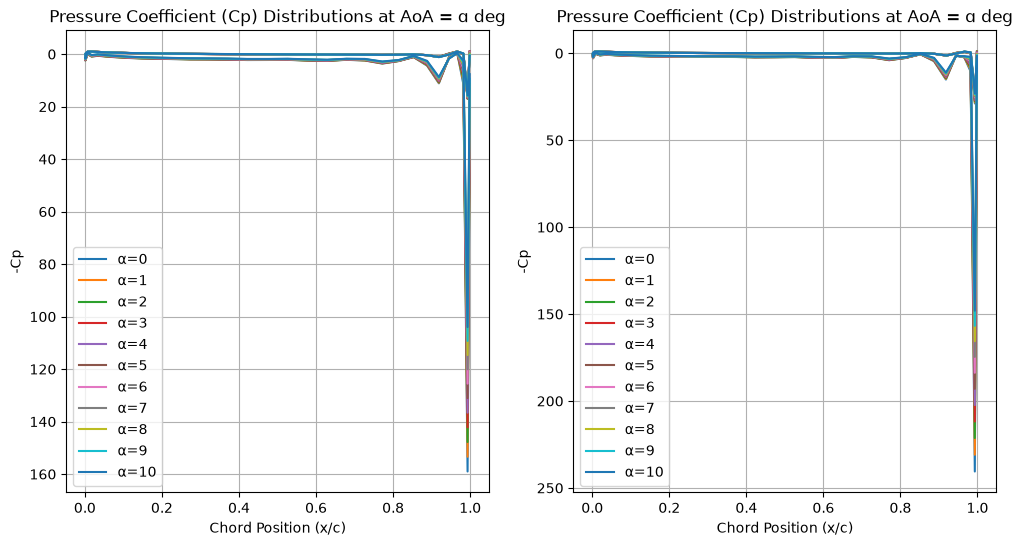

In [42]:
X_sym, Y_sym = Air_foil(60, 'symmetric')
X_asym, Y_asym = Air_foil(60, 'asymmetric')

alp = np.array([0,1,2,3,4,5,6,7,8,9,10])

plt.figure(figsize=(12, 6))
plt.subplot(1,2,1)
for i in range(len(α)):
    _, _, cp_sym, cl_sym, _, xc_sym, _ = vortex_panel_method_0(X_sym, Y_sym, alp[i])
    plt.plot(xc_sym, -cp_sym, label=f'α={alp[i]}')
    plt.gca().invert_yaxis()
    
plt.title('Pressure Coefficient (Cp) Distributions at AoA = ɑ deg')
plt.xlabel('Chord Position (x/c)')
plt.ylabel('-Cp')
plt.legend()
plt.grid(True)

plt.subplot(1,2,2)
for i in range(len(α)):
    _, _, cp_asym, cl_asym, _, xc_asym, _ = vortex_panel_method_0(X_asym, Y_asym, alp[i])
    plt.plot(xc_asym, -cp_asym, label=f'α={alp[i]}')
    plt.gca().invert_yaxis()
    
plt.title('Pressure Coefficient (Cp) Distributions at AoA = ɑ deg')
plt.xlabel('Chord Position (x/c)')
plt.ylabel('-Cp')
plt.legend()
plt.grid(True)
plt.show()

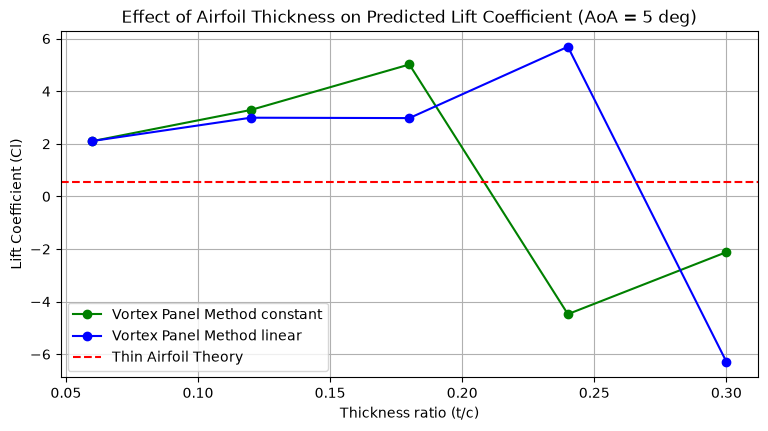

In [43]:

thickness_values = [0.06, 0.12, 0.18, 0.24, 0.30]
cl_vs_thickness0 = []
cl_vs_thickness1 = []

for t_val in thickness_values:
    n_pts = 60
    i = int(n_pts / 2)
    a = np.linspace(0, np.pi, i + 1)
    x = 0.5 * (1 - np.cos(a))
    y_t = 5 * t_val * (0.2969 * (x**0.5) - 0.1260 * x - 0.3516 * (x**2) + 0.2843 * (x**3) - 0.1036 * (x**4))
    X_t = np.concatenate([np.flip(x), x[1:]])
    Y_t = np.concatenate([-np.flip(y_t), y_t[1:]])

    _, _, _, cl_thick0, _, _, _ = vortex_panel_method_0(X_t, Y_t, 5.0) 
    cl_vs_thickness0.append(cl_thick0)
    _, _, _, cl_thick1, _, _, _ = vortex_panel_method_1(X_t, Y_t, 5.0) 
    cl_vs_thickness1.append(cl_thick1)


cl_theoretical = 2.0 * np.pi * np.deg2rad(5.0)

plt.figure(figsize=(9, 4.5))
plt.plot(thickness_values, cl_vs_thickness0, 'o-g', label='Vortex Panel Method constant')
plt.plot(thickness_values, cl_vs_thickness1, 'o-b', label='Vortex Panel Method linear')
plt.axhline(y=cl_theoretical, color='red', linestyle='--', label='Thin Airfoil Theory ')
plt.title('Effect of Airfoil Thickness on Predicted Lift Coefficient (AoA = 5 deg)')
plt.xlabel('Thickness ratio (t/c)')
plt.ylabel('Lift Coefficient (Cl)')
plt.legend()
plt.grid(True)
plt.show()

# Results and discussion

# Summary and conculsions

# References

1) Fundamentals of Aerodynamics - John D. Anderson (chapter 3, section 3.17)
2) Panel methods playlist from JoshTheEngineer - [link](https://youtube.com/playlist?list=PLxT-itJ3HGuUDVMuWKBxyoY8Dm9O9qstP&si=62FYJ0FNjdFVGrCj)
3) Airfoil plotting Function - comprehensive work interpolation

### AI Acknowledgement 
Generative AI were used at points when I felt stuck, and for plot generation